In [ ]:
# Install the libraries used in this notebook
!pip -q install kagglehub pytorch-tabnet

In [ ]:
import os
import glob
import copy
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc
)
from sklearn.inspection import permutation_importance

import kagglehub
from pytorch_tabnet.tab_model import TabNetClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.1+cpu
Device: cpu


In [ ]:
dataset_path = kagglehub.dataset_download("iabhishekofficial/mobile-price-classification")
print("Dataset downloaded to:", dataset_path)

csv_files = glob.glob(os.path.join(dataset_path, "**", "*.csv"), recursive=True)
print("CSV files found:", csv_files)

# The Kaggle dataset normally includes train.csv and test.csv.
# train.csv contains the labelled records and is used for this academic classification task.
train_csv = next((p for p in csv_files if os.path.basename(p).lower() == "train.csv"), None)
if train_csv is None:
    raise FileNotFoundError("Could not find train.csv in the downloaded dataset.")

df = pd.read_csv(train_csv)
print("Dataset shape:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'mobile-price-classification' dataset.
Dataset downloaded to: /kaggle/input/mobile-price-classification
CSV files found: ['/kaggle/input/mobile-price-classification/train.csv', '/kaggle/input/mobile-price-classification/test.csv']
Dataset shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [ ]:
display(df.info())
display(df.describe().T)
print("Columns:", df.columns.tolist())
print("Target classes:", sorted(df["price_range"].unique()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

None

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


Columns: ['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi', 'price_range']
Target classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


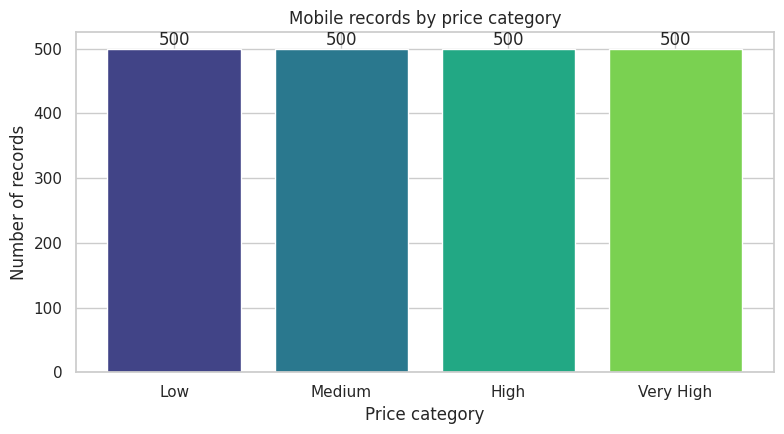

In [ ]:
# Target category distribution
class_names = ["Low", "Medium", "High", "Very High"]
class_counts = df["price_range"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(class_names, class_counts.values, color=sns.color_palette("viridis", 4))
ax.set_title("Mobile records by price category")
ax.set_xlabel("Price category")
ax.set_ylabel("Number of records")
for bar, value in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.show()

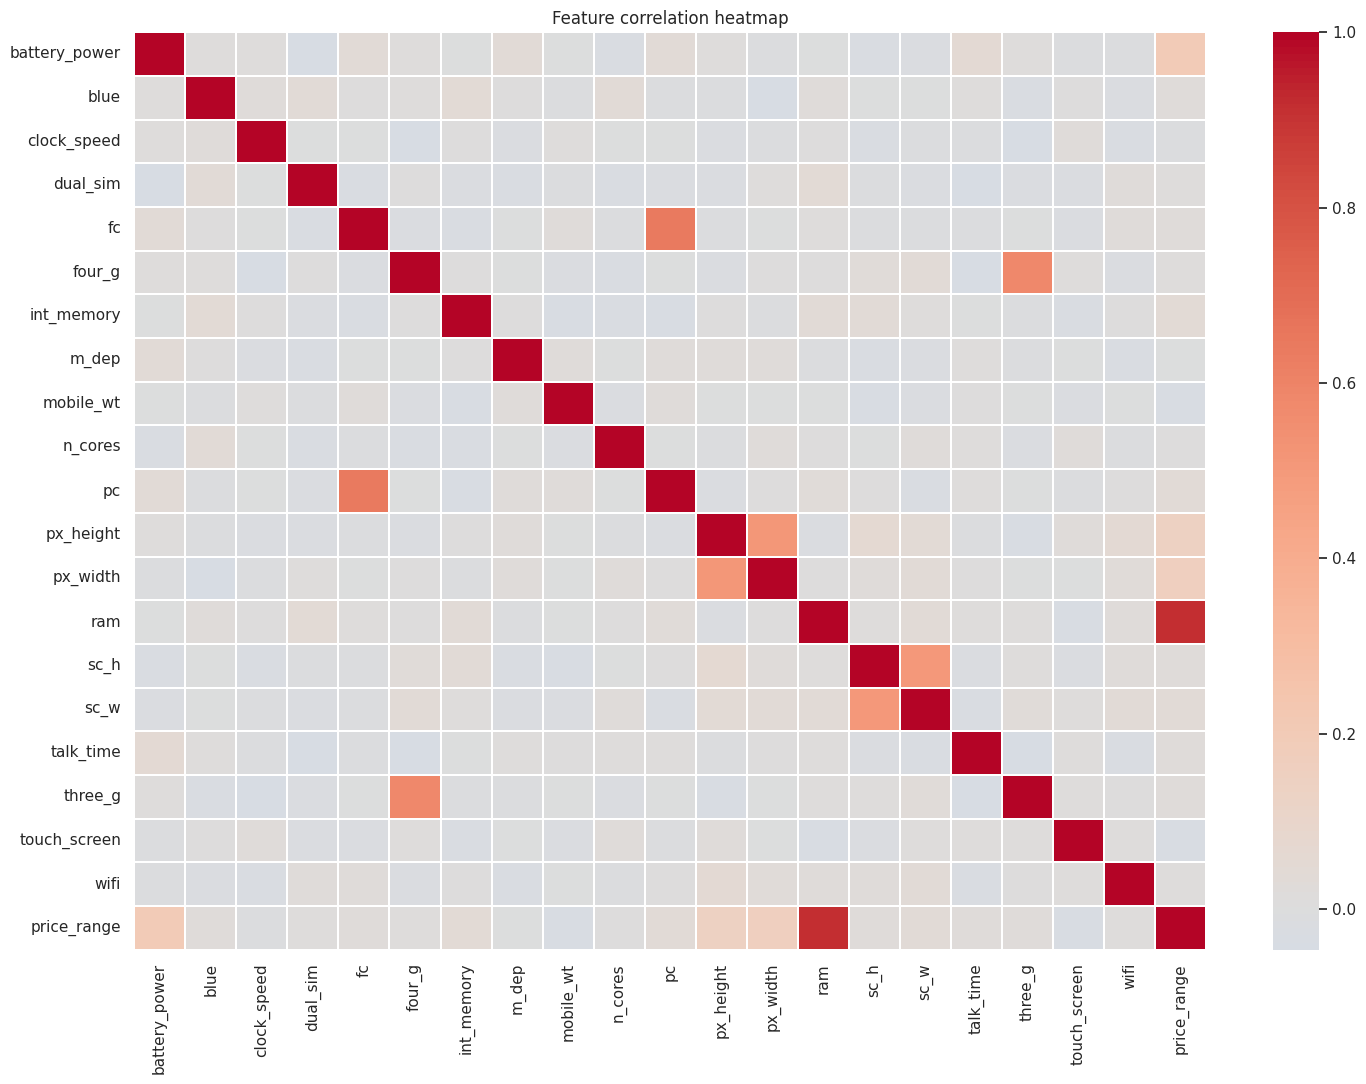

In [ ]:
# Correlation heatmap
plt.figure(figsize=(15, 11))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.25)
plt.title("Feature correlation heatmap")
plt.tight_layout()
plt.show()

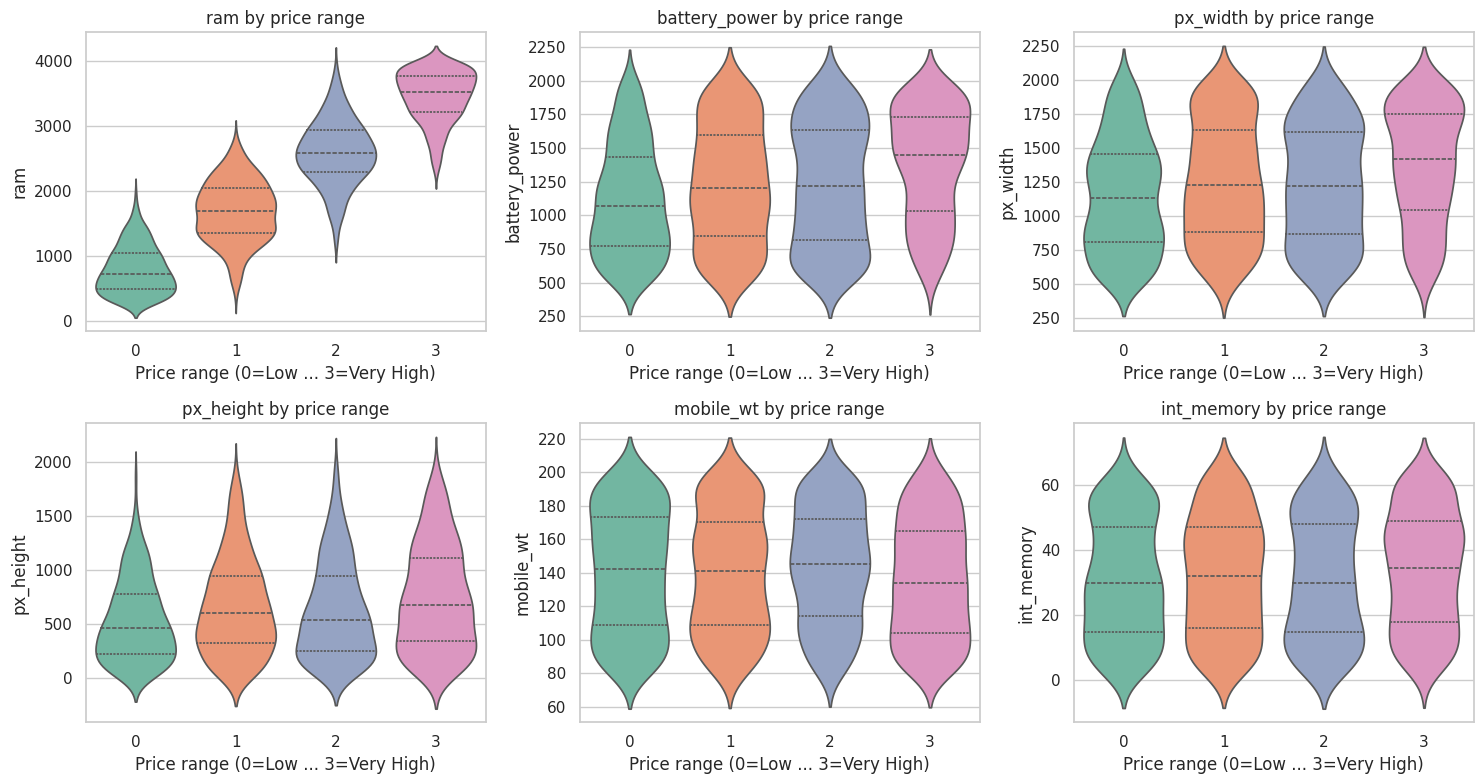

In [ ]:
# Distributions of selected features by price range
selected_features = ["ram", "battery_power", "px_width", "px_height", "mobile_wt", "int_memory"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.flat, selected_features):
    sns.violinplot(data=df, x="price_range", y=feature, ax=ax, inner="quartile", palette="Set2")
    ax.set_title(f"{feature} by price range")
    ax.set_xlabel("Price range (0=Low ... 3=Very High)")
plt.tight_layout()
plt.show()

In [ ]:
print("Missing values before cleaning:", int(df.isna().sum().sum()))
print("Duplicate rows before cleaning:", int(df.duplicated().sum()))

df = df.drop_duplicates().copy()
df = df.dropna().copy()

target_col = "price_range"
expected_classes = {0, 1, 2, 3}
if set(df[target_col].unique()) != expected_classes:
    raise ValueError(f"Expected target classes {expected_classes}, got {set(df[target_col].unique())}")

X = df.drop(columns=[target_col]).copy()
y = df[target_col].astype(int).copy()

# Convert any unexpected non-numeric predictor columns, then check for invalid values.
X = X.apply(pd.to_numeric, errors="coerce")
if X.isna().any().any():
    raise ValueError("Missing or non-numeric feature values remain after conversion.")

print("Feature matrix:", X.shape)
print("Target distribution:")
print(y.value_counts().sort_index())

Missing values before cleaning: 0
Duplicate rows before cleaning: 0
Feature matrix: (2000, 20)
Target distribution:
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


In [ ]:
# 70% train, 30% temporary; then split temporary equally into validation and test.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

print("Train:", X_train_scaled.shape, "Validation:", X_val_scaled.shape, "Test:", X_test_scaled.shape)
print("Train class proportions:", np.bincount(y_train_np) / len(y_train_np))
print("Validation class proportions:", np.bincount(y_val_np) / len(y_val_np))
print("Test class proportions:", np.bincount(y_test_np) / len(y_test_np))

feature_names = X.columns.tolist()
n_features = X_train_scaled.shape[1]
n_classes = len(np.unique(y_train_np))

Train: (1400, 20) Validation: (300, 20) Test: (300, 20)
Train class proportions: [0.25 0.25 0.25 0.25]
Validation class proportions: [0.25 0.25 0.25 0.25]
Test class proportions: [0.25 0.25 0.25 0.25]


In [ ]:
def make_loaders(Xtr, ytr, Xv, yv, batch_size=64):
    train_ds = TensorDataset(torch.tensor(Xtr, dtype=torch.float32),
                             torch.tensor(ytr, dtype=torch.long))
    val_ds = TensorDataset(torch.tensor(Xv, dtype=torch.float32),
                           torch.tensor(yv, dtype=torch.long))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    return train_loader, val_loader

def evaluate_torch(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total

def train_torch_model(model, train_loader, val_loader, epochs=150,
                      lr=1e-3, weight_decay=1e-4, patience=20):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    wait = 0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)

        train_loss = running_loss / total
        train_acc = correct / total
        val_loss, val_acc = evaluate_torch(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss - 1e-5:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1:03d} | train loss {train_loss:.4f} | "
                  f"val loss {val_loss:.4f} | train acc {train_acc:.4f} | val acc {val_acc:.4f}")
        if wait >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    model.load_state_dict(best_state)
    return model, history

def torch_predict_proba(model, X_array, batch_size=256):
    model.eval()
    loader = DataLoader(TensorDataset(torch.tensor(X_array, dtype=torch.float32)),
                        batch_size=batch_size, shuffle=False)
    outputs = []
    with torch.no_grad():
        for (xb,) in loader:
            logits = model(xb.to(DEVICE))
            outputs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.vstack(outputs)

In [ ]:
class ANN(nn.Module):
    def __init__(self, input_dim, num_classes=4, dropout=0.25):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)

train_loader, val_loader = make_loaders(
    X_train_scaled, y_train_np, X_val_scaled, y_val_np, batch_size=64
)

ann_model = ANN(n_features, n_classes)
ann_model, ann_history = train_torch_model(
    ann_model, train_loader, val_loader,
    epochs=150, lr=1e-3, weight_decay=1e-4, patience=20
)

Epoch 010 | train loss 0.3888 | val loss 0.2989 | train acc 0.8464 | val acc 0.8900
Epoch 020 | train loss 0.2853 | val loss 0.1964 | train acc 0.8786 | val acc 0.9300
Epoch 030 | train loss 0.2722 | val loss 0.1808 | train acc 0.8986 | val acc 0.9267
Epoch 040 | train loss 0.1751 | val loss 0.1868 | train acc 0.9350 | val acc 0.9167
Epoch 050 | train loss 0.1762 | val loss 0.1699 | train acc 0.9329 | val acc 0.9300
Epoch 060 | train loss 0.1632 | val loss 0.1846 | train acc 0.9414 | val acc 0.9200
Epoch 070 | train loss 0.1589 | val loss 0.1579 | train acc 0.9357 | val acc 0.9333
Epoch 080 | train loss 0.2136 | val loss 0.1879 | train acc 0.9264 | val acc 0.9267
Epoch 090 | train loss 0.1538 | val loss 0.1791 | train acc 0.9443 | val acc 0.9167
Early stopping at epoch 90


In [ ]:
# TabNet is a PyTorch-based attentive architecture designed for tabular data.
tabnet_model = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=4,
    gamma=1.5,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax",
    seed=SEED,
    verbose=10,
    device_name="auto"
)

tabnet_model.fit(
    X_train=X_train_scaled,
    y_train=y_train_np,
    eval_set=[
        (X_train_scaled, y_train_np),
        (X_val_scaled, y_val_np)
    ],
    eval_name=["train", "valid"],
    eval_metric=["accuracy"],
    max_epochs=200,
    patience=25,
    batch_size=256,
    virtual_batch_size=64,
    num_workers=0,
    drop_last=False
)

epoch 0  | loss: 1.63704 | train_accuracy: 0.33571 | valid_accuracy: 0.37    |  0:00:00s
epoch 10 | loss: 0.5325  | train_accuracy: 0.77929 | valid_accuracy: 0.76    |  0:00:04s
epoch 20 | loss: 0.41082 | train_accuracy: 0.855   | valid_accuracy: 0.81667 |  0:00:07s
epoch 30 | loss: 0.38045 | train_accuracy: 0.87929 | valid_accuracy: 0.87333 |  0:00:10s
epoch 40 | loss: 0.27001 | train_accuracy: 0.92    | valid_accuracy: 0.90333 |  0:00:13s
epoch 50 | loss: 0.24954 | train_accuracy: 0.94071 | valid_accuracy: 0.90667 |  0:00:17s
epoch 60 | loss: 0.20712 | train_accuracy: 0.95857 | valid_accuracy: 0.92667 |  0:00:20s
epoch 70 | loss: 0.18559 | train_accuracy: 0.95429 | valid_accuracy: 0.89667 |  0:00:23s
epoch 80 | loss: 0.2128  | train_accuracy: 0.96929 | valid_accuracy: 0.89    |  0:00:26s

Early stopping occurred at epoch 86 with best_epoch = 61 and best_valid_accuracy = 0.93


In [ ]:
class FTTransformer(nn.Module):
    def __init__(self, n_features, num_classes=4, d_token=64,
                 n_heads=4, n_layers=2, dropout=0.15):
        super().__init__()
        self.feature_weight = nn.Parameter(torch.randn(n_features, d_token) * 0.02)
        self.feature_bias = nn.Parameter(torch.zeros(n_features, d_token))
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_token))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token,
            nhead=n_heads,
            dim_feedforward=d_token * 2,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Sequential(
            nn.Linear(d_token, d_token),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_token, num_classes)
        )

    def forward(self, x):
        # x: [batch, features] -> tokens: [batch, features, d_token]
        tokens = x.unsqueeze(-1) * self.feature_weight.unsqueeze(0) + self.feature_bias.unsqueeze(0)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        tokens = torch.cat([cls, tokens], dim=1)
        encoded = self.transformer(tokens)
        return self.head(self.norm(encoded[:, 0]))

ft_model = FTTransformer(
    n_features=n_features, num_classes=n_classes,
    d_token=64, n_heads=4, n_layers=2, dropout=0.15
)
ft_model, ft_history = train_torch_model(
    ft_model, train_loader, val_loader,
    epochs=180, lr=5e-4, weight_decay=1e-4, patience=25
)

Epoch 010 | train loss 0.2290 | val loss 0.2389 | train acc 0.9121 | val acc 0.8967
Epoch 020 | train loss 0.1671 | val loss 0.2109 | train acc 0.9314 | val acc 0.9067
Epoch 030 | train loss 0.1307 | val loss 0.2161 | train acc 0.9493 | val acc 0.9167
Epoch 040 | train loss 0.1712 | val loss 0.2478 | train acc 0.9279 | val acc 0.9167
Epoch 050 | train loss 0.1109 | val loss 0.2372 | train acc 0.9607 | val acc 0.9133
Early stopping at epoch 57


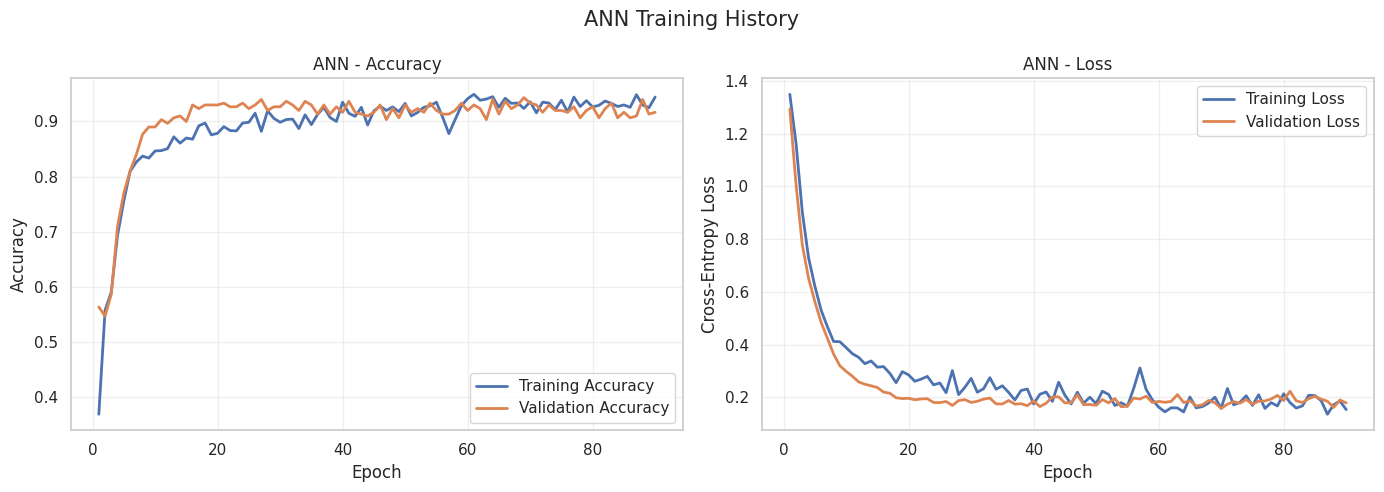

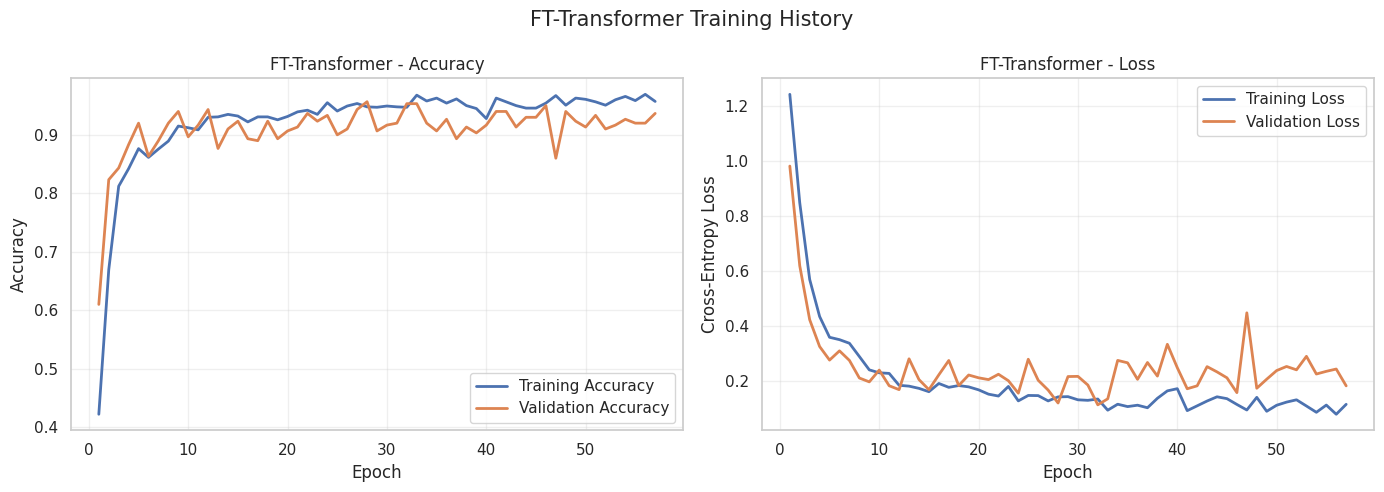

In [ ]:
# ANN and FT-Transformer Training Curves

def plot_training_history(history, model_name):
    epochs = np.arange(1, len(history["train_acc"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, history["train_acc"], linewidth=2, label="Training Accuracy")
    axes[0].plot(epochs, history["val_acc"], linewidth=2, label="Validation Accuracy")
    axes[0].set_title(f"{model_name} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history["train_loss"], linewidth=2, label="Training Loss")
    axes[1].plot(epochs, history["val_loss"], linewidth=2, label="Validation Loss")
    axes[1].set_title(f"{model_name} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Cross-Entropy Loss")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(f"{model_name} Training History", fontsize=15)
    plt.tight_layout()
    plt.show()

plot_training_history(ann_history, "ANN")
plot_training_history(ft_history, "FT-Transformer")


TabNet history keys: ['loss', 'lr', 'train_accuracy', 'valid_accuracy']


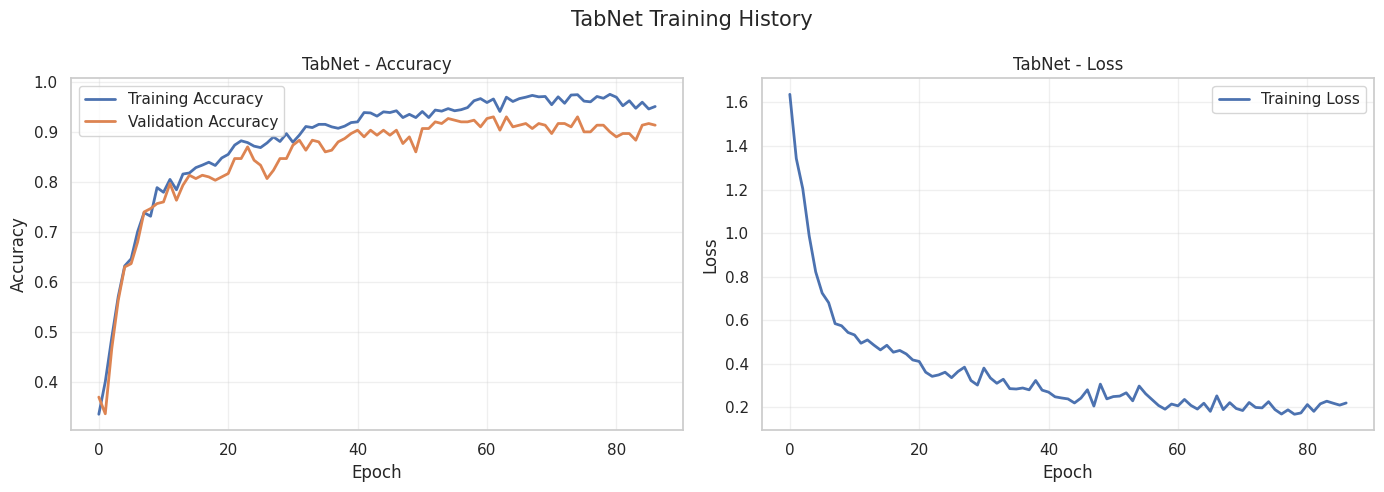

In [ ]:
# TabNet Training Curves

tabnet_history = tabnet_model.history.history
print("TabNet history keys:", list(tabnet_history.keys()))

def find_history_key(history_dict, candidates):
    for key in candidates:
        if key in history_dict:
            return key
    return None

train_acc_key = find_history_key(tabnet_history, ["train_accuracy", "train_acc"])
val_acc_key = find_history_key(tabnet_history, ["valid_accuracy", "valid_acc"])
train_loss_key = find_history_key(tabnet_history, ["loss"])
val_loss_key = find_history_key(tabnet_history, ["valid_logloss", "valid_loss"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if train_acc_key and val_acc_key:
    axes[0].plot(tabnet_history[train_acc_key], linewidth=2, label="Training Accuracy")
    axes[0].plot(tabnet_history[val_acc_key], linewidth=2, label="Validation Accuracy")
    axes[0].legend()
else:
    axes[0].text(0.5, 0.5, "Accuracy history unavailable", ha="center", va="center")
axes[0].set_title("TabNet - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].grid(alpha=0.3)

if train_loss_key:
    axes[1].plot(tabnet_history[train_loss_key], linewidth=2, label="Training Loss")
if val_loss_key:
    axes[1].plot(tabnet_history[val_loss_key], linewidth=2, label="Validation Loss")
axes[1].set_title("TabNet - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle("TabNet Training History", fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:
# Test probabilities and class predictions
ann_test_proba = torch_predict_proba(ann_model, X_test_scaled)
ft_test_proba = torch_predict_proba(ft_model, X_test_scaled)
tabnet_test_proba = tabnet_model.predict_proba(X_test_scaled)

test_probabilities = {
    "ANN": ann_test_proba,
    "TabNet": tabnet_test_proba,
    "FT-Transformer": ft_test_proba
}

def calculate_metrics(y_true, probabilities):
    predictions = probabilities.argmax(axis=1)
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision (macro)": precision_score(y_true, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, predictions, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_true, predictions, average="macro", zero_division=0),
        "ROC-AUC (macro OVR)": roc_auc_score(
            y_true, probabilities, multi_class="ovr", average="macro"
        )
    }

metrics = {
    name: calculate_metrics(y_test_np, proba)
    for name, proba in test_probabilities.items()
}
results_df = pd.DataFrame(metrics).T
display(results_df.style.format("{:.4f}"))

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),ROC-AUC (macro OVR)
ANN,0.9167,0.9170,0.9167,0.9167,0.9929
TabNet,0.9300,0.9307,0.9300,0.9303,0.9927
FT-Transformer,0.9467,0.9493,0.9467,0.9468,0.9977


In [ ]:
for name, probabilities in test_probabilities.items():
    print("\\n" + "="*65)
    print(name)
    print("="*65)
    print(classification_report(
        y_test_np,
        probabilities.argmax(axis=1),
        labels=[0, 1, 2, 3],
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

\n=================================================================
ANN
              precision    recall  f1-score   support

         Low     0.9595    0.9467    0.9530        75
      Medium     0.9041    0.8800    0.8919        75
        High     0.8701    0.8933    0.8816        75
   Very High     0.9342    0.9467    0.9404        75

    accuracy                         0.9167       300
   macro avg     0.9170    0.9167    0.9167       300
weighted avg     0.9170    0.9167    0.9167       300

\n=================================================================
TabNet
              precision    recall  f1-score   support

         Low     0.9863    0.9600    0.9730        75
      Medium     0.9459    0.9333    0.9396        75
        High     0.8816    0.8933    0.8874        75
   Very High     0.9091    0.9333    0.9211        75

    accuracy                         0.9300       300
   macro avg     0.9307    0.9300    0.9303       300
weighted avg     0.9307    0.9300    0

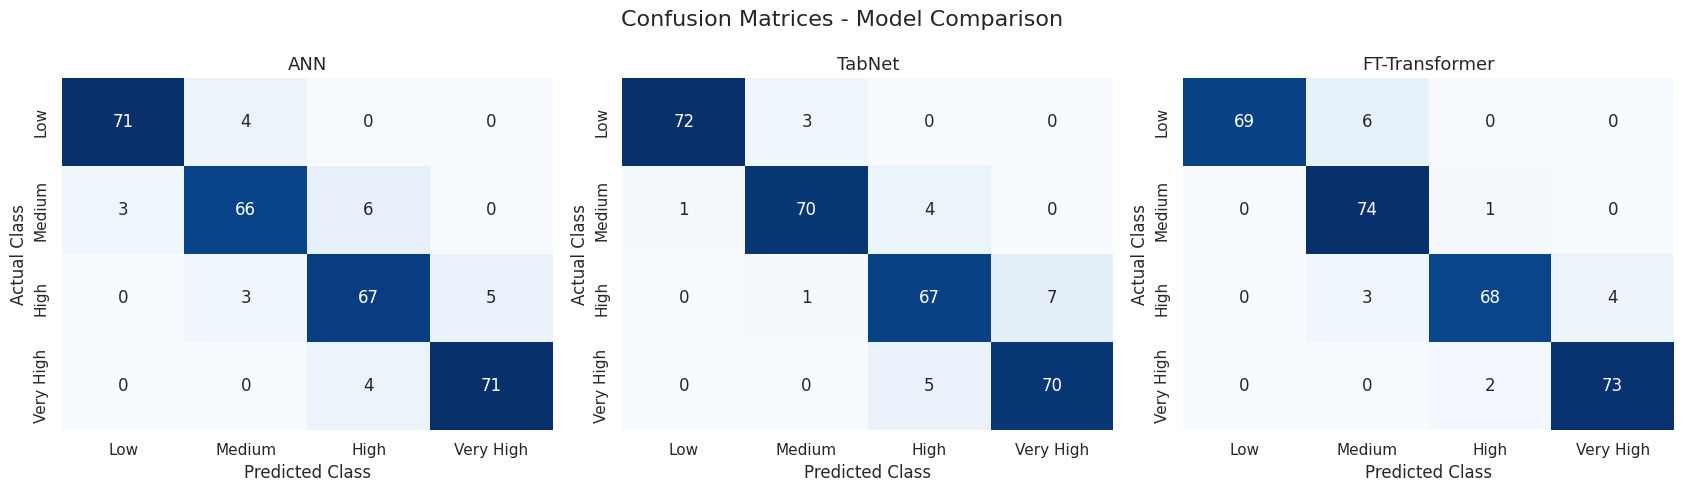

In [ ]:
# Confusion Matrix Comparison

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, probabilities) in zip(axes, test_probabilities.items()):
    cm = confusion_matrix(y_test_np, probabilities.argmax(axis=1), labels=[0, 1, 2, 3])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name, fontsize=13)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
plt.suptitle("Confusion Matrices - Model Comparison", fontsize=16)
plt.tight_layout()
plt.show()


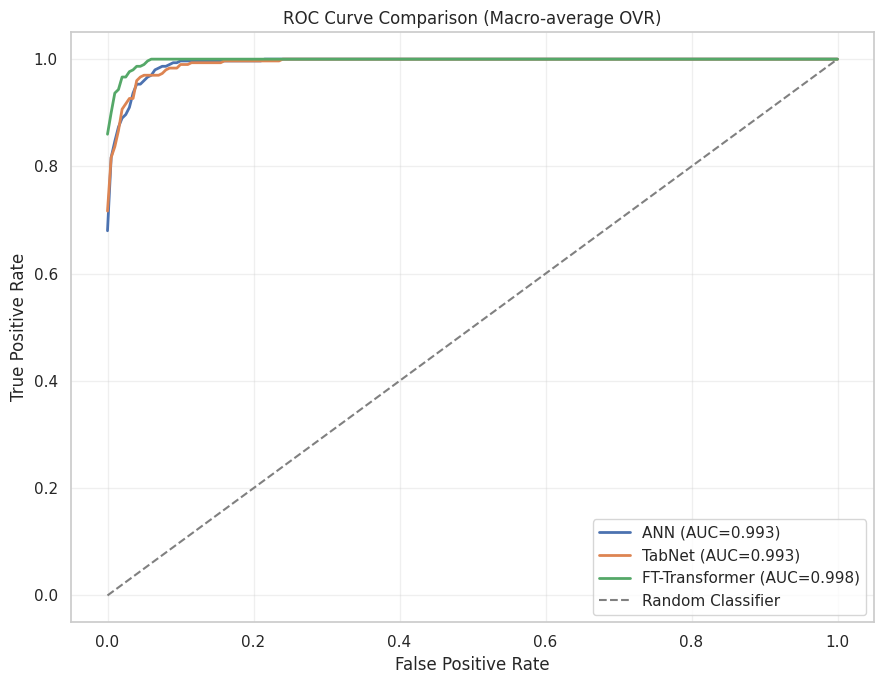

In [ ]:
# Macro-average ROC Curves - One vs Rest

y_test_bin = label_binarize(y_test_np, classes=[0, 1, 2, 3])
fig, ax = plt.subplots(figsize=(9, 7))
fpr_grid = np.linspace(0, 1, 201)

for name, probabilities in test_probabilities.items():
    tprs = []
    for class_idx in range(4):
        fpr, tpr, _ = roc_curve(y_test_bin[:, class_idx], probabilities[:, class_idx])
        tprs.append(np.interp(fpr_grid, fpr, tpr))
    mean_tpr = np.mean(tprs, axis=0)
    macro_auc = auc(fpr_grid, mean_tpr)
    ax.plot(fpr_grid, mean_tpr, linewidth=2, label=f"{name} (AUC={macro_auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Comparison (Macro-average OVR)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


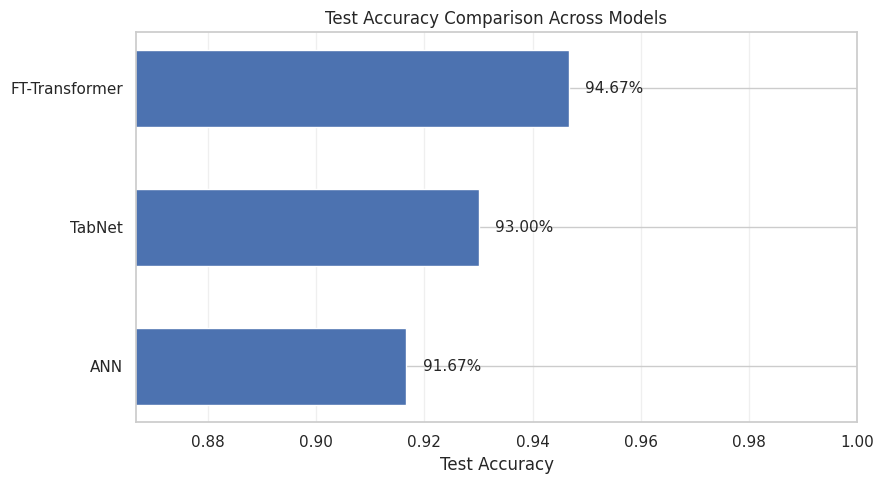

In [ ]:
# Test Accuracy Comparison - Horizontal Bar Chart

accuracy_values = results_df["Accuracy"].sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(accuracy_values.index, accuracy_values.values, height=0.55)
ax.set_xlabel("Test Accuracy")
ax.set_title("Test Accuracy Comparison Across Models")
ax.set_xlim(max(0, accuracy_values.min() - 0.05), min(1.0, accuracy_values.max() + 0.06))
for bar, value in zip(bars, accuracy_values.values):
    ax.text(value + 0.003, bar.get_y() + bar.get_height()/2, f"{value*100:.2f}%", va="center", fontsize=11)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


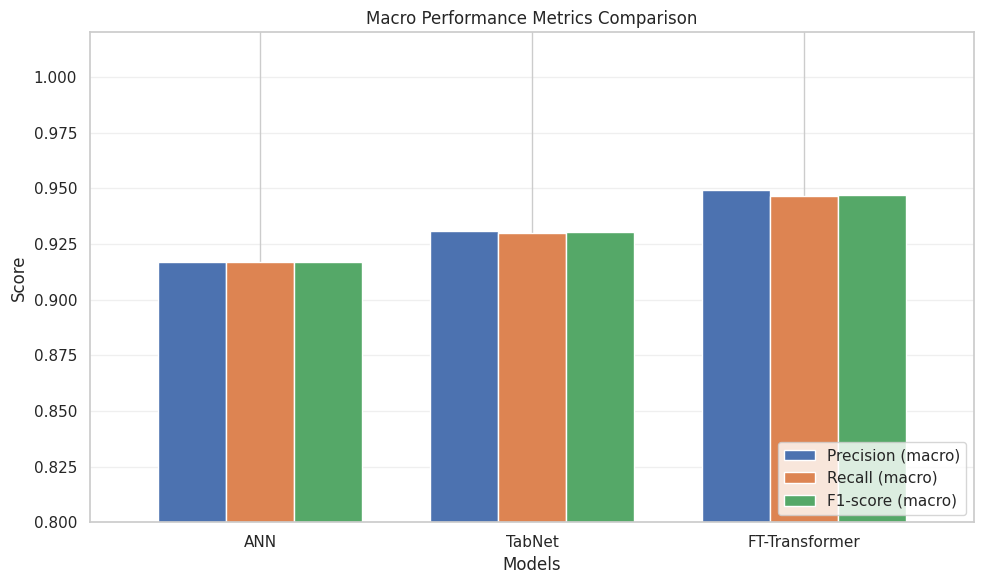

In [ ]:
# Precision, Recall and F1-score Comparison

comparison = results_df[["Precision (macro)", "Recall (macro)", "F1-score (macro)"]]
ax = comparison.plot(kind="bar", figsize=(10, 6), width=0.75)
ax.set_title("Macro Performance Metrics Comparison")
ax.set_xlabel("Models")
ax.set_ylabel("Score")
ax.set_ylim(0.80, 1.02)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


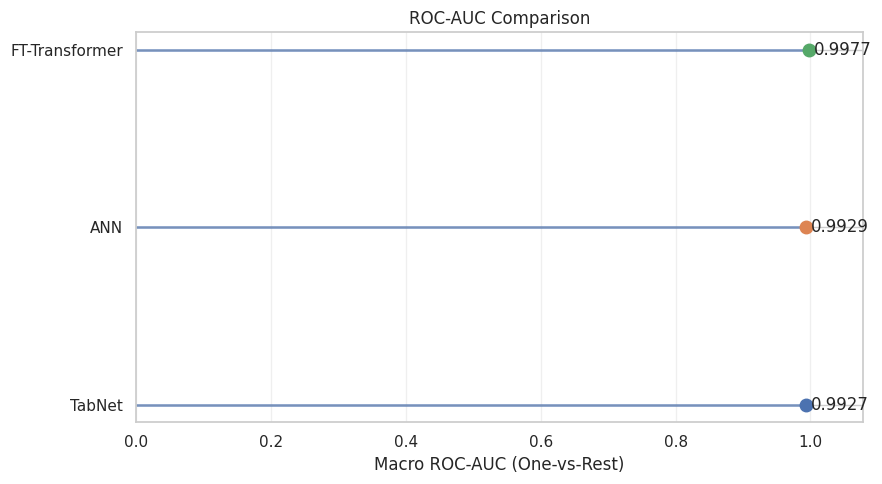

In [ ]:
# ROC-AUC Score Comparison - Lollipop Chart

auc_values = results_df["ROC-AUC (macro OVR)"].sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
for y_pos, (model_name, value) in enumerate(auc_values.items()):
    ax.hlines(y_pos, 0, value, linewidth=2, alpha=0.65)
    ax.plot(value, y_pos, marker="o", markersize=9)
    ax.text(value + 0.008, y_pos, f"{value:.4f}", va="center")
ax.set_yticks(range(len(auc_values)))
ax.set_yticklabels(auc_values.index)
ax.set_xlim(0, min(1.10, auc_values.max() + 0.08))
ax.set_xlabel("Macro ROC-AUC (One-vs-Rest)")
ax.set_title("ROC-AUC Comparison")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


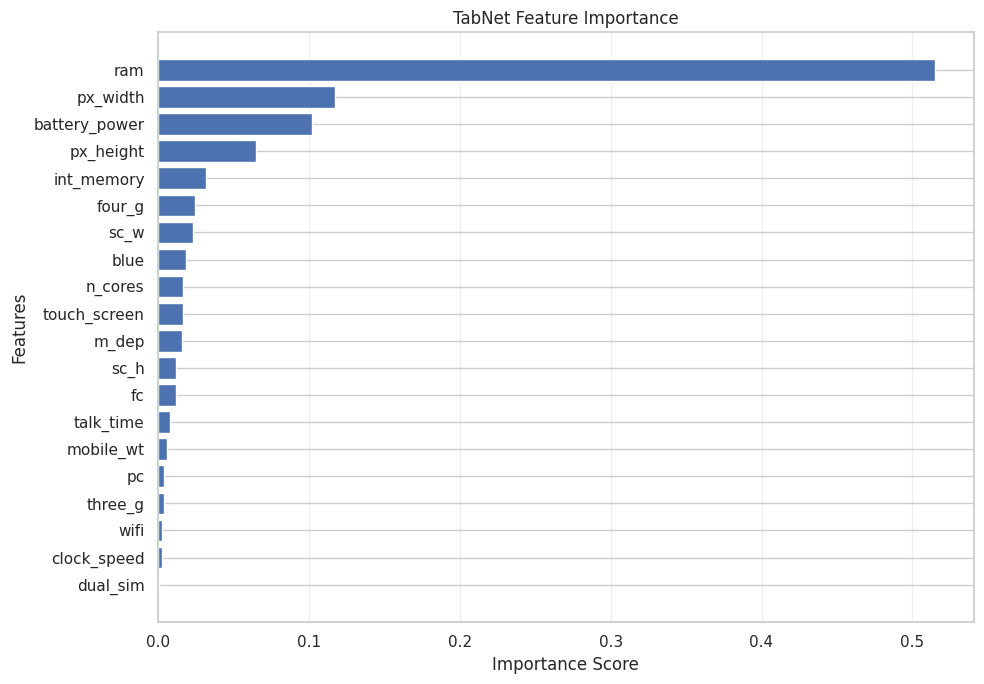

In [ ]:
# TabNet Feature Importance

tabnet_importance = pd.Series(tabnet_model.feature_importances_, index=feature_names).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(tabnet_importance.index, tabnet_importance.values)
ax.set_title("TabNet Feature Importance")
ax.set_xlabel("Importance Score")
ax.set_ylabel("Features")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


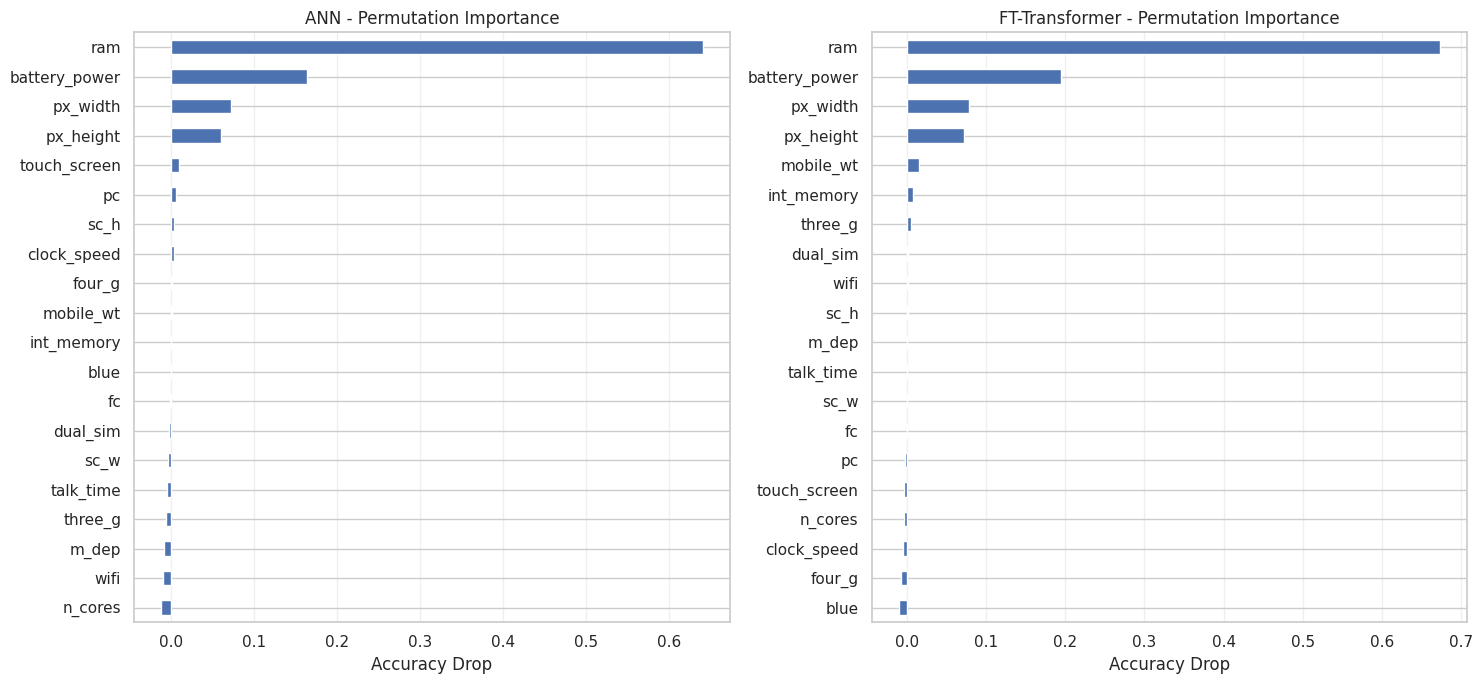

In [ ]:
# Permutation Importance for ANN and FT-Transformer

def predict_ann_labels(X_array):
    return torch_predict_proba(ann_model, X_array).argmax(axis=1)

def predict_ft_labels(X_array):
    return torch_predict_proba(ft_model, X_array).argmax(axis=1)

def manual_permutation_importance(predict_fn, X_array, y_true, feature_names, n_repeats=5, seed=SEED):
    rng = np.random.default_rng(seed)
    baseline = accuracy_score(y_true, predict_fn(X_array))
    drops = []
    for j, feature in enumerate(feature_names):
        scores = []
        for _ in range(n_repeats):
            X_perm = X_array.copy()
            X_perm[:, j] = rng.permutation(X_perm[:, j])
            scores.append(accuracy_score(y_true, predict_fn(X_perm)))
        drops.append(baseline - np.mean(scores))
    return pd.Series(drops, index=feature_names).sort_values(ascending=True)

ann_importance = manual_permutation_importance(predict_ann_labels, X_test_scaled, y_test_np, feature_names)
ft_importance = manual_permutation_importance(predict_ft_labels, X_test_scaled, y_test_np, feature_names)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
ann_importance.plot(kind="barh", ax=axes[0])
axes[0].set_title("ANN - Permutation Importance")
axes[0].set_xlabel("Accuracy Drop")
ft_importance.plot(kind="barh", ax=axes[1])
axes[1].set_title("FT-Transformer - Permutation Importance")
axes[1].set_xlabel("Accuracy Drop")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Validation probabilities for model selection
ann_val_proba = torch_predict_proba(ann_model, X_val_scaled)
ft_val_proba = torch_predict_proba(ft_model, X_val_scaled)
tabnet_val_proba = tabnet_model.predict_proba(X_val_scaled)

validation_probabilities = {
    "ANN": ann_val_proba,
    "TabNet": tabnet_val_proba,
    "FT-Transformer": ft_val_proba
}

validation_f1 = {
    name: f1_score(y_val_np, p.argmax(axis=1), average="macro", zero_division=0)
    for name, p in validation_probabilities.items()
}
print("Validation macro F1:", validation_f1)

best_model_name = max(validation_f1, key=validation_f1.get)
print("Selected model:", best_model_name)

os.makedirs("saved_models", exist_ok=True)
if best_model_name == "ANN":
    torch.save(ann_model.state_dict(), "saved_models/best_ann.pth")
elif best_model_name == "FT-Transformer":
    torch.save(ft_model.state_dict(), "saved_models/best_ft_transformer.pth")
else:
    tabnet_model.save_model("saved_models/best_tabnet")

import joblib
joblib.dump(scaler, "saved_models/standard_scaler.joblib")
joblib.dump(feature_names, "saved_models/feature_names.joblib")
joblib.dump(class_names, "saved_models/class_names.joblib")

print("Model and preprocessing artifacts saved in ./saved_models/")

Validation macro F1: {'ANN': 0.9330073170355895, 'TabNet': 0.9294977850002599, 'FT-Transformer': 0.95327754373807}
Selected model: FT-Transformer
Model and preprocessing artifacts saved in ./saved_models/


In [ ]:
print("FINAL TEST RESULTS")
display(results_df.sort_values("Accuracy", ascending=False).style.format("{:.4f}"))

print("\\nModel selected using validation macro F1:", best_model_name)
print("Validation macro F1:", round(validation_f1[best_model_name], 4))

best_test_accuracy = results_df.loc[best_model_name, "Accuracy"]
print("Selected model test accuracy:", round(best_test_accuracy, 4))

print("\\nSuggested conclusion:")
print(
    f"The three deep-learning models were trained and evaluated using the same "
    f"stratified data split. {best_model_name} achieved the highest validation "
    f"macro F1-score and was selected for saving. Its held-out test accuracy was "
    f"{best_test_accuracy:.4f}. The final comparison should also consider macro "
    f"precision, recall, F1-score and ROC-AUC, as well as the confusion matrices "
    f"and feature-contribution plots. Results are specific to this dataset and split."
)

FINAL TEST RESULTS


,Accuracy,Precision (macro),Recall (macro),F1-score (macro),ROC-AUC (macro OVR)
FT-Transformer,0.9467,0.9493,0.9467,0.9468,0.9977
TabNet,0.9300,0.9307,0.9300,0.9303,0.9927
ANN,0.9167,0.9170,0.9167,0.9167,0.9929


\nModel selected using validation macro F1: FT-Transformer
Validation macro F1: 0.9533
Selected model test accuracy: 0.9467
\nSuggested conclusion:
The three deep-learning models were trained and evaluated using the same stratified data split. FT-Transformer achieved the highest validation macro F1-score and was selected for saving. Its held-out test accuracy was 0.9467. The final comparison should also consider macro precision, recall, F1-score and ROC-AUC, as well as the confusion matrices and feature-contribution plots. Results are specific to this dataset and split.


In [ ]:
import shutil
zip_path = shutil.make_archive("mobile_price_prediction_models", "zip", "saved_models")
print("Created:", zip_path)

# In Google Colab, uncomment the next two lines to download the ZIP:
# from google.colab import files
# files.download(zip_path)

Created: /content/mobile_price_prediction_models.zip


In [ ]:
# Example input row: replace these values with the actual mobile specifications.
# Column order is taken directly from the dataset.
sample_mobile = pd.DataFrame([{
    "battery_power": 1200, "blue": 1, "clock_speed": 2.0, "dual_sim": 1,
    "fc": 5, "four_g": 1, "int_memory": 32, "m_dep": 0.5,
    "mobile_wt": 150, "n_cores": 4, "pc": 13, "px_height": 900,
    "px_width": 1500, "ram": 2000, "sc_h": 15, "sc_w": 7,
    "talk_time": 10, "three_g": 1, "touch_screen": 1, "wifi": 1
}])[feature_names]

sample_scaled = scaler.transform(sample_mobile).astype(np.float32)

if best_model_name == "ANN":
    sample_proba = torch_predict_proba(ann_model, sample_scaled)
elif best_model_name == "FT-Transformer":
    sample_proba = torch_predict_proba(ft_model, sample_scaled)
else:
    sample_proba = tabnet_model.predict_proba(sample_scaled)

predicted_class = int(sample_proba.argmax(axis=1)[0])
print("Predicted price range:", class_names[predicted_class])
print("Class probabilities:", dict(zip(class_names, sample_proba[0].round(4))))

Predicted price range: Medium
Class probabilities: {'Low': np.float32(0.0006), 'Medium': np.float32(0.9727), 'High': np.float32(0.0265), 'Very High': np.float32(1e-04)}
